# Lab3: Multiple Linear Regression with PyTorch — Predicting Food Delivery Time

**Topics covered:** the *concise* (high-level) way of building a linear regression model in
PyTorch using `torch.nn`, plus a full discussion of **generalization**: training error vs.
generalization error, the train/validation/test split, underfitting vs. overfitting, the
effect of model capacity and dataset size, and regularization (weight decay).

**Dataset:** [Food Delivery Time Prediction](https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction)
(Kaggle, by denkuznetz). Each row is one delivery order, described by numeric and categorical
features, with the target `Delivery_Time_min` — the total delivery time in minutes.

| Column | Type | Description |
|---|---|---|
| `Order_ID` | id | unique order identifier (not a feature) |
| `Distance_km` | numeric | distance from restaurant to customer |
| `Weather` | categorical | Clear, Rainy, Snowy, Foggy, Windy |
| `Traffic_Level` | categorical | Low, Medium, High |
| `Time_of_Day` | categorical | Morning, Afternoon, Evening, Night |
| `Vehicle_Type` | categorical | Bike, Scooter, Car |
| `Preparation_Time_min` | numeric | time the restaurant needs to prepare the order |
| `Courier_Experience_yrs` | numeric | courier's experience, in years |
| `Delivery_Time_min` | numeric (**target**) | total delivery duration |

### Learning objectives
By the end of this lab you will be able to:
1. Build and preprocess a real-world tabular dataset for a regression task (missing values,
   categorical encoding, feature scaling).
2. Implement multiple linear regression **concisely** in PyTorch with `nn.Linear`,
   `nn.MSELoss`, and an optimizer from `torch.optim` — instead of hand-writing gradients.
3. Train the model with mini-batch SGD using `Dataset` / `DataLoader`.
4. Explain and *observe* the difference between **training error** and **generalization
   (test) error**.


> Every step is implemented with standard
> `torch`, `pandas`, and `scikit-learn` (scikit-learn is only used for splitting data and
> preprocessing — the model itself is pure PyTorch).


## 0. Setup

Install/import the libraries we need.
- `torch` does the modeling
- `pandas`/`numpy` do the data wrangling
- `scikit-learn` gives us convenient (non-modeling) helpers for splitting and
encoding data
- and `matplotlib` is for plotting loss curves.


In [3]:
# If running on Google Colab or a fresh environment, uncomment the line below:
# !pip install torch pandas numpy scikit-learn matplotlib -q

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Reproducibility: fix every source of randomness we control.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


ModuleNotFoundError: No module named 'torch'

## 1. Load the dataset

**Instructions**
1. Go to the Kaggle dataset page:
   <https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction>
2. Download `Food_Delivery_Times.csv` (click "Download").
3. Place the CSV file in the **same folder as this notebook**.

The cell below looks for a handful of likely file names. If it can't find the real file
(e.g., you're running this in a sandbox without the download), it will fall back to
generating a small **synthetic** dataset with the exact same columns and a similar amount
of noise, purely so the rest of the notebook still runs end-to-end for demonstration. Make
sure you replace this with the real CSV before drawing real conclusions!


In [3]:
import os
# Read dataset from the downloaded file.
dataset_file = "Food_Delivery_Times.csv"
df = pd.read_csv(dataset_file)
df.head()


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## 2. Explore the data (EDA)

Before touching any model, always look at the data: shape, types, missing values, and how
the target is distributed. This also tells us which columns are numeric and which are
categorical, which we'll need for preprocessing.


In [4]:
print("Shape:", df.shape)
df.info()


Shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Distance_km,1000.0,NaN,NaN,NaN,10.05997,5.696656,0.59,5.105,10.19,15.0175,19.99
Weather,970,5,Clear,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Traffic_Level,970,3,Medium,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_of_Day,970,4,Morning,308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,1000,3,Bike,503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preparation_Time_min,1000.0,NaN,NaN,NaN,16.982,7.204553,5.0,11.0,17.0,23.0,29.0
Courier_Experience_yrs,970.0,NaN,NaN,NaN,4.579381,2.914394,0.0,2.0,5.0,7.0,9.0
Delivery_Time_min,1000.0,NaN,NaN,NaN,56.732,22.070915,8.0,41.0,55.5,71.0,153.0


In [6]:
#check missing values by columns

print("Missing values per column:")
print(df.isna().sum())


Missing values per column:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


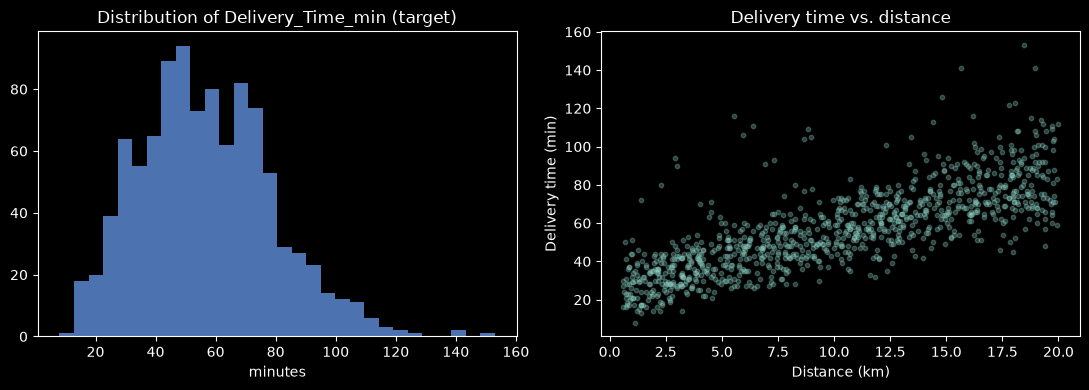

In [7]:
# Exploratory Data Analysis (EDA)
# Before training the model, we visualize the data to:
# 1. Understand the distribution of the target variable (Delivery_Time_min).
# 2. Check whether Distance_km has a relationship with delivery time.
# 3. Identify possible unusual values or patterns in the dataset.

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["Delivery_Time_min"].dropna(), bins=30, color="#4C72B0")
axes[0].set_title("Distribution of Delivery_Time_min (target)")
axes[0].set_xlabel("minutes")


# Plot graph to see relationship between distance and delivery time
# For linear regression, we are interested in whether the
# relationship shows an approximately linear trend.

axes[1].scatter(df["Distance_km"], df["Delivery_Time_min"], alpha=0.3, s=10)
axes[1].set_title("Delivery time vs. distance")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Delivery time (min)")
plt.tight_layout()
plt.show()


** Correlation heatmap **

A correlation heatmap summarizes the linear relationship among all numerical features and the target.

For our dataset:



In [8]:
# Select numerical features and target
numeric_df = df[
    [
        "Distance_km",
        "Preparation_Time_min",
        "Courier_Experience_yrs",
        "Delivery_Time_min"
    ]
]

# Calculate correlation matrix
corr = numeric_df.corr()

corr

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
Distance_km,1.000000,-0.009037,-0.007842,0.780998
Preparation_Time_min,-0.009037,1.000000,-0.030830,0.307350
Courier_Experience_yrs,-0.007842,-0.030830,1.000000,-0.090433
Delivery_Time_min,0.780998,0.307350,-0.090433,1.000000


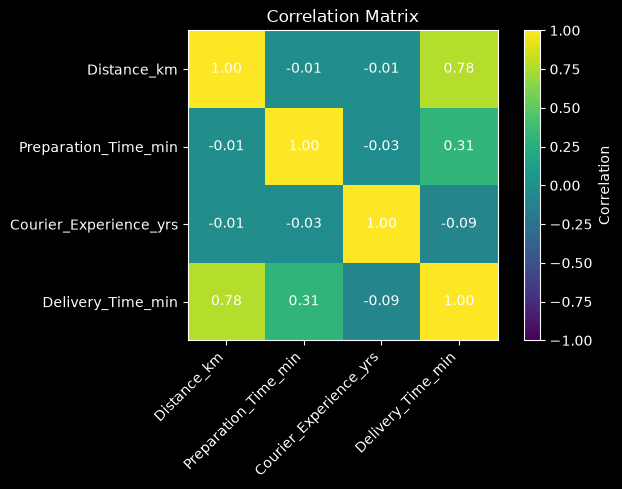

In [9]:
#Correlation heatmap: A correlation heatmap summarizes the linear relationship among all numerical features and the target.

import matplotlib.pyplot as plt
import numpy as np

corr = numeric_df.corr()
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(corr, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

# Display correlation values
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

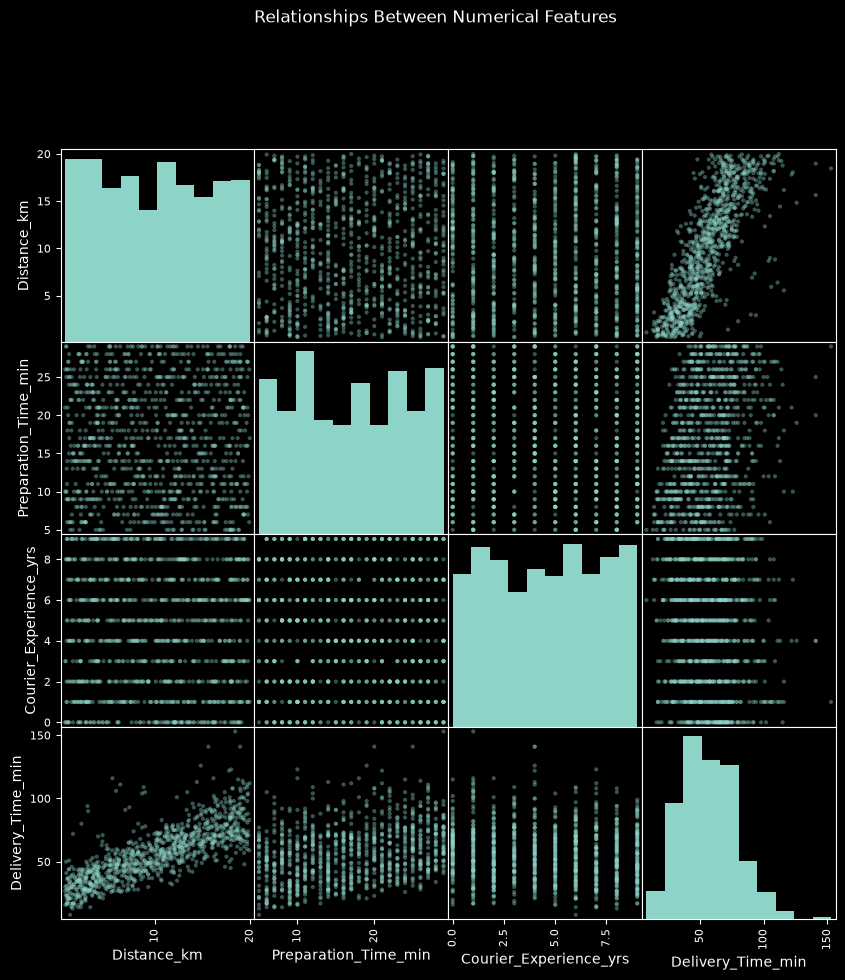

In [10]:
# Actual data points.
from pandas.plotting import scatter_matrix

scatter_matrix(
    numeric_df,
    figsize=(10, 10),
    alpha=0.4,
    diagonal="hist"
)

plt.suptitle(
    "Relationships Between Numerical Features",
    y=1.02
)

plt.show()

## 3. Preprocess the data

Three things need to happen before this data can feed a linear model:

1. **Handle missing values.** The simplest, most transparent option for a lab is to drop
   rows with missing values (there are usually very few). In a production pipeline you might
   impute instead.

2. **Encode categorical features — but not all the same way.**
   - `Weather`, `Vehicle_Type`, and `Time_of_Day` are treated as **nominal** here and get
     **one-hot encoding**, which creates one independent binary column per category and
     imposes no ordering. (`Time_of_Day` *looks* ordered, but it's actually cyclical — Night
     is followed by Morning again — and its effect on delivery time is likely non-monotonic,
     e.g. slow during morning *and* evening rush, faster mid-day and at night. A monotonic
     encoding can't represent that two-peaked pattern, so we keep it one-hot. See the
     discussion cell right after the preprocessing code for the full reasoning.)
   - `Traffic_Level` (Low < Medium < High) **is** genuinely ordinal — more congestion is
     unambiguously "more traffic" — so we use **thermometer (cumulative / unary) encoding**
     for it instead of one-hot.

   **What thermometer encoding is.** For an ordinal feature with *k* levels, we use *k − 1*
   binary columns. Level *i* (0-indexed) is represented by *i* ones followed by zeros. For
   `Traffic_Level`:

   | Level  | col: `>=Medium` | col: `>=High` |
   |--------|:---:|:---:|
   | Low    | 0 | 0 |
   | Medium | 1 | 0 |
   | High   | 1 | 1 |

   Compare this with plain integer encoding (Low=0, Medium=1, High=2), which forces the model
   to use a *single* weight and therefore assume the jump from Low→Medium costs exactly the
   same as Medium→High. Thermometer encoding gives each *step* its own weight — the model can
   learn that, say, Low→Medium adds 3 minutes while Medium→High adds 9 — while still encoding
   the fact that High implies Medium implies Low (monotonicity), which one-hot encoding does
   not represent at all.

3. **Scale numeric features.** `Distance_km`, `Preparation_Time_min`, and
   `Courier_Experience_yrs` live on very different scales. Gradient descent converges much
   faster and more reliably when every input feature has roughly zero mean and unit
   variance — this is exactly what `StandardScaler` does. Without it, a feature measured in
   the tens (distance) can dominate the loss surface compared with a feature measured in
   single digits (experience), forcing us to use a tiny learning rate.

We drop `Order_ID` — it's just a row identifier with no predictive meaning.


In [11]:
df_clean = df.drop(columns=["Order_ID"]).dropna().reset_index(drop=True)
print(f"Rows before dropping NaNs: {len(df)}  |  after: {len(df_clean)}")

TARGET = "Delivery_Time_min"
NUMERIC_FEATURES = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]

# Nominal categorical features (including Time_of_Day — see markdown above for why):
# no monotonic effect assumed -> one-hot encoding.
NOMINAL_FEATURES = ["Weather", "Vehicle_Type", "Time_of_Day"]

# Ordinal categorical feature: natural order AND a plausibly monotonic effect
# -> thermometer encoding. The list is the order from "lowest" to "highest" level.
ORDINAL_FEATURES = {
    "Traffic_Level": ["Low", "Medium", "High"],
}

CATEGORICAL_FEATURES = NOMINAL_FEATURES + list(ORDINAL_FEATURES.keys())

X = df_clean[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df_clean[TARGET].astype(np.float32).values.reshape(-1, 1)

print("Feature matrix shape:", X.shape, " | Target shape:", y.shape)

X


Rows before dropping NaNs: 1000  |  after: 883
Feature matrix shape: (883, 7)  | Target shape: (883, 1)


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Weather,Vehicle_Type,Time_of_Day,Traffic_Level
0,7.93,12,1.0,Windy,Scooter,Afternoon,Low
1,16.42,20,2.0,Clear,Bike,Evening,Medium
2,9.52,28,1.0,Foggy,Scooter,Night,Low
3,7.44,5,1.0,Rainy,Scooter,Afternoon,Medium
4,19.03,16,5.0,Clear,Bike,Morning,Low
...,...,...,...,...,...,...,...
878,8.50,13,3.0,Clear,Car,Evening,High
879,16.28,8,9.0,Rainy,Scooter,Morning,Low
880,15.62,26,2.0,Snowy,Scooter,Evening,High
881,14.17,8,0.0,Clear,Bike,Afternoon,Low


## 4. Split the data: train / validation / test

This is where **generalization** starts to matter, so let's slow down.

- The **training set** is what the optimizer sees. The model's parameters are updated to
  minimize the loss *on this data only*.
- The **training error** (the loss computed on the training set) tells us how well the model
  fits the data it has already seen. It is an optimistic, biased estimate of how good the
  model really is, because the parameters were chosen specifically to make this number small.
- What we actually care about is the **generalization error**: how well the model performs
  on *new, unseen* data drawn from the same underlying distribution. We approximate this
  with a **held-out test set** that the model never touches during training or tuning.
- But if we peeked at the test set every time we tried a new hyperparameter (learning rate,
  regularization strength, feature set, ...), we would slowly overfit *to the test set*
  itself, and it would stop being an honest estimate of generalization. That's why we
  introduce a **third split**: the **validation set**. We use it to compare models/settings
  and pick the best one; the test set is only ever touched **once**, at the very end.

A common split is 70% train / 15% validation / 15% test. We use `train_test_split` twice to
get there.


In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print(f"Train: {len(X_train)}  |  Validation: {len(X_val)}  |  Test: {len(X_test)}")


Train: 618  |  Validation: 132  |  Test: 133



Now fit the preprocessing (`StandardScaler` mean/std, `OneHotEncoder` categories)
**only on the training set**, and apply the same transformation to validation and test.

This is important: if we fit the scaler on the *entire* dataset before splitting, information
from the validation/test rows (their mean, their standard deviation, which categories exist)
would leak into training. That's a subtle but common way people accidentally inflate their
reported generalization performance.


In [13]:
from sklearn.base import BaseEstimator, TransformerMixin


class ThermometerEncoder(BaseEstimator, TransformerMixin):
    """Cumulative / unary ("thermometer") encoding for a single ordinal column.

    For k ordered levels, produces k-1 binary columns. Level i (0-indexed) is encoded
    as i ones followed by zeros, e.g. for ["Low", "Medium", "High"]:
        Low    -> [0, 0]
        Medium -> [1, 0]
        High   -> [1, 1]
    Each column effectively asks "is the level at least this high?" — the model learns
    one weight per *step*, instead of one weight for the whole scale as with a single
    integer column, while still respecting the fact that High implies Medium implies Low.

    Unseen categories at transform time fall back to the top level (all ones), which is
    a safe default for a monotonic feature; unlike OneHotEncoder(handle_unknown="ignore"),
    a thermometer code always produces a valid, in-range encoding, never an all-zero
    "unknown" row.
    """

    def __init__(self, categories_in_order):
        # Store the constructor argument UNMODIFIED (no copying/casting here) — scikit-learn's
        # get_params()/clone() machinery requires every __init__ argument to be saved as-is.
        self.categories_in_order = categories_in_order

    def fit(self, X, y=None):
        self.categories_ = list(self.categories_in_order)
        self.n_levels_ = len(self.categories_)
        self.index_ = {c: i for i, c in enumerate(self.categories_)}
        return self

    def transform(self, X):
        values = np.asarray(X).reshape(-1)
        n = len(values)
        out = np.zeros((n, self.n_levels_ - 1), dtype=np.float32)
        for row, val in enumerate(values):
            idx = self.index_.get(val, self.n_levels_ - 1)  # unseen -> treat as top level
            out[row, :idx] = 1.0
        return out

    def get_feature_names_out(self, input_features=None):
        base = input_features[0] if input_features else "x"
        return np.array([f"{base}>={self.categories_[i + 1]}" for i in range(self.n_levels_ - 1)])


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), NOMINAL_FEATURES),
        ("traffic_thermo", ThermometerEncoder(ORDINAL_FEATURES["Traffic_Level"]), ["Traffic_Level"]),
    ]
)

X_train_np = preprocessor.fit_transform(X_train)   # fit ONLY on training data
X_val_np = preprocessor.transform(X_val)           # reuse the same fitted transform
X_test_np = preprocessor.transform(X_test)

# ColumnTransformer may return a sparse matrix depending on sklearn version/encoders used
X_train_np = np.asarray(X_train_np, dtype=np.float32)
X_val_np = np.asarray(X_val_np, dtype=np.float32)
X_test_np = np.asarray(X_test_np, dtype=np.float32)

n_features = X_train_np.shape[1]
print("Number of input features after encoding:", n_features)
print("Feature names:", preprocessor.get_feature_names_out())

X_train_np


Number of input features after encoding: 17
Feature names: ['num__Distance_km' 'num__Preparation_Time_min'
 'num__Courier_Experience_yrs' 'nominal__Weather_Clear'
 'nominal__Weather_Foggy' 'nominal__Weather_Rainy'
 'nominal__Weather_Snowy' 'nominal__Weather_Windy'
 'nominal__Vehicle_Type_Bike' 'nominal__Vehicle_Type_Car'
 'nominal__Vehicle_Type_Scooter' 'nominal__Time_of_Day_Afternoon'
 'nominal__Time_of_Day_Evening' 'nominal__Time_of_Day_Morning'
 'nominal__Time_of_Day_Night' 'traffic_thermo__Traffic_Level>=Medium'
 'traffic_thermo__Traffic_Level>=High']


array([[ 0.26409963, -0.9462405 ,  0.48729292, ...,  0.        ,
         1.        ,  0.        ],
       [-0.37448698,  0.970611  , -0.20341125, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.49166226,  1.1075289 ,  1.1779971 , ...,  0.        ,
         1.        ,  1.        ],
       ...,
       [-0.42388043, -1.0831584 ,  1.1779971 , ...,  0.        ,
         1.        ,  0.        ],
       [ 0.7209889 , -0.8093225 ,  1.5233492 , ...,  0.        ,
         1.        ,  0.        ],
       [-0.37272295, -0.26165065, -1.2394675 , ...,  0.        ,
         0.        ,  0.        ]], dtype=float32)

## 5. From NumPy to PyTorch: `Dataset` and `DataLoader`

PyTorch's *concise* API for feeding data to a model in mini-batches has two building blocks:

- **`TensorDataset`**: wraps tensors so that indexing `dataset[i]` returns `(features_i, label_i)`.
- **`DataLoader`**: wraps a `Dataset` and handles batching, shuffling, and iteration for us,
  so we don't write a manual mini-batch loop with array slicing.

We shuffle the training loader (so batches aren't correlated with the original row order),
but not the validation/test loaders (no need — we're only reading loss, not learning).


In [14]:
def to_tensor(array):
    return torch.tensor(array, dtype=torch.float32)

train_ds = TensorDataset(to_tensor(X_train_np), to_tensor(y_train))
val_ds = TensorDataset(to_tensor(X_val_np), to_tensor(y_val))
test_ds = TensorDataset(to_tensor(X_test_np), to_tensor(y_test))

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Sanity check: look at one batch
xb, yb = next(iter(train_loader))
print("Batch of features:", xb.shape, "| Batch of targets:", yb.shape)


Batch of features: torch.Size([32, 17]) | Batch of targets: torch.Size([32, 1])


## 6. Define the model — the concise PyTorch way

Multiple linear regression predicts

$$\hat{y} = \mathbf{w}^\top \mathbf{x} + b = w_1 x_1 + w_2 x_2 + \dots + w_d x_d + b$$

Rather than manually creating `w` and `b` tensors and writing out the matrix multiplication
ourselves, we use `torch.nn.Linear(in_features, out_features)`. A single `nn.Linear` layer
*is* multiple linear regression: it stores a weight matrix and a bias vector, and computes
exactly the expression above during its forward pass. This is the "concise" style: build the
model out of pre-made layers, let `nn.MSELoss` compute the loss, and let `torch.optim` compute
the parameter updates — no manual gradients.


In [15]:
class LinearRegressionModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x)


def build_model(n_features, lr=0.01, weight_decay=0.0):
    '''Factory so we can easily rebuild a fresh model for each experiment.'''
    torch.manual_seed(SEED)
    model = LinearRegressionModel(n_features).to(device)
    # Initialize weights small and bias at zero (helps a stable start for gradient descent)
    nn.init.normal_(model.linear.weight, mean=0.0, std=0.01)
    nn.init.zeros_(model.linear.bias)
    loss_fn = nn.MSELoss()
    # Best practice: apply weight decay to the WEIGHTS only, not the bias. The bias just
    # shifts predictions by a constant (here, roughly the average delivery time); shrinking
    # it toward zero doesn't fight overfitting, it just adds a large, useless bias error.
    optimizer = torch.optim.SGD(
        [
            {"params": [model.linear.weight], "weight_decay": weight_decay},
            {"params": [model.linear.bias], "weight_decay": 0.0},
        ],
        lr=lr,
    )
    return model, loss_fn, optimizer


model, loss_fn, optimizer = build_model(n_features, lr=0.05)
print(model)


LinearRegressionModel(
  (linear): Linear(in_features=17, out_features=1, bias=True)
)


## 7. The training loop

Each epoch:
1. Loop over mini-batches from `train_loader`, do a forward pass, compute the loss, call
   `loss.backward()`, then `optimizer.step()` (and `optimizer.zero_grad()` beforehand).
2. After the epoch, evaluate the model on the **validation set** with `torch.no_grad()`
   (no gradient tracking needed — we're only reading, not learning). We track both the
   training loss and the validation loss every epoch: comparing the two curves is exactly
   how we will diagnose over/underfitting in the next section.


In [16]:
def epoch_loss(model, loader, loss_fn):
    '''Average loss of `model` over an entire DataLoader, without updating parameters.'''
    model.eval()
    total_loss, total_count = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = loss_fn(preds, yb)
            total_loss += loss.item() * xb.size(0)
            total_count += xb.size(0)
    return total_loss / total_count


def train(model, loss_fn, optimizer, train_loader, val_loader, n_epochs=100, verbose=True):
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(1, n_epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = loss_fn(preds, yb)
            loss.backward()
            optimizer.step()

        train_l = epoch_loss(model, train_loader, loss_fn)
        val_l = epoch_loss(model, val_loader, loss_fn)
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)

        if verbose and (epoch % max(1, n_epochs // 10) == 0 or epoch == 1):
            print(f"epoch {epoch:4d} | train MSE {train_l:8.3f} | val MSE {val_l:8.3f}")
    return history


## 8. Train the baseline model

Let's train our multiple linear regression model and plot the training vs. validation loss
curves. If the model is well specified and not overfitting, both curves should decrease
together and settle close to each other.


In [17]:
model, loss_fn, optimizer = build_model(n_features, lr=0.05)
history = train(model, loss_fn, optimizer, train_loader, val_loader, n_epochs=150)

# This lab trains a single baseline model, so it also serves as our "best" model for the
# final test-set evaluation below. (In a fuller lab you would compare several
# hyperparameter settings on the validation set first, then assign whichever one wins to
# `best_model`.)
best_model = model


epoch    1 | train MSE  156.938 | val MSE  120.375
epoch   15 | train MSE  113.374 | val MSE   93.947
epoch   30 | train MSE  111.713 | val MSE   93.989
epoch   45 | train MSE  113.175 | val MSE   97.507
epoch   60 | train MSE  112.866 | val MSE   95.285
epoch   75 | train MSE  111.809 | val MSE   92.778
epoch   90 | train MSE  114.955 | val MSE   92.820
epoch  105 | train MSE  111.907 | val MSE   93.657
epoch  120 | train MSE  116.802 | val MSE  100.501
epoch  135 | train MSE  111.863 | val MSE   92.791
epoch  150 | train MSE  115.823 | val MSE   99.903


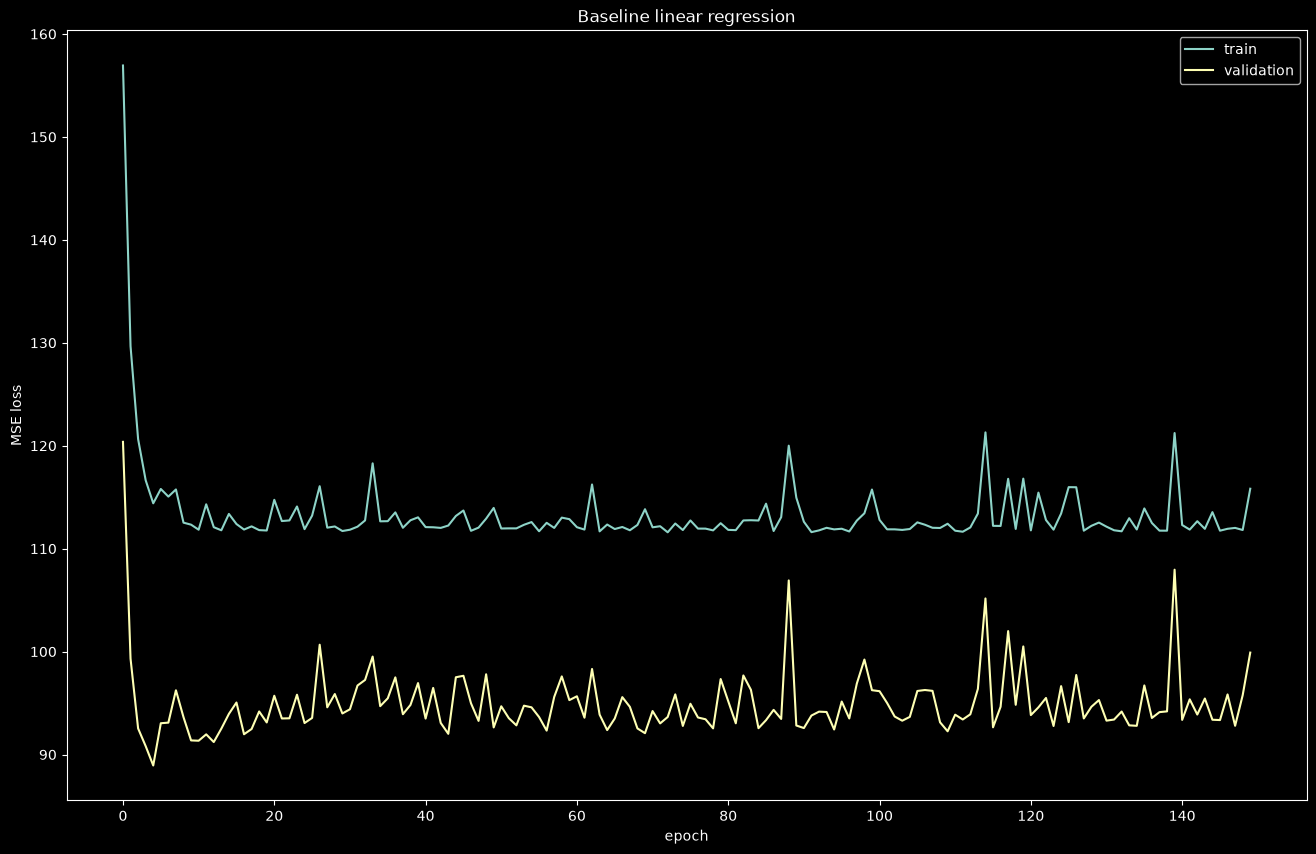

In [20]:
def plot_history(history, title="Training vs. validation loss"):
    plt.figure(figsize=(16, 10))
    plt.plot(history["train_loss"], label="train")
    plt.plot(history["val_loss"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("MSE loss")
    plt.title(title)
    plt.legend()
    plt.show()

plot_history(history, "Baseline linear regression")


**What to look for:** with a correctly specified linear model and enough data, the train
and validation curves should converge close together. A visible, *persistent* gap where
validation loss stays noticeably above training loss is a symptom of overfitting; both
curves staying high and flat is a symptom of underfitting. We'll now engineer both of these
situations on purpose so you can recognize them.


## 11. Final evaluation on the test set

The test set has not influenced any decision so far — not the parameters, not the
hyperparameters. This is the one and only time we touch it, and the resulting numbers are
our best honest estimate of how this model will perform on new, real deliveries.

We report three complementary metrics:
- **MAE** (mean absolute error): average error in minutes — easy to interpret.
- **RMSE** (root mean squared error): like MAE but penalizes large errors more.
- **R²**: proportion of variance in delivery time explained by the model (1.0 is perfect,
  0.0 means "no better than always predicting the mean").


In [21]:
best_model.eval()
with torch.no_grad():
    X_test_t = to_tensor(X_test_np).to(device)
    y_pred_test = best_model(X_test_t).cpu().numpy()

mae = mean_absolute_error(y_test, y_pred_test)
rmse = mean_squared_error(y_test, y_pred_test) ** 0.5
r2 = r2_score(y_test, y_pred_test)

print(f"Test MAE : {mae:.2f} minutes")
print(f"Test RMSE: {rmse:.2f} minutes")
print(f"Test R^2 : {r2:.3f}")


Test MAE : 5.35 minutes
Test RMSE: 7.32 minutes
Test R^2 : 0.882


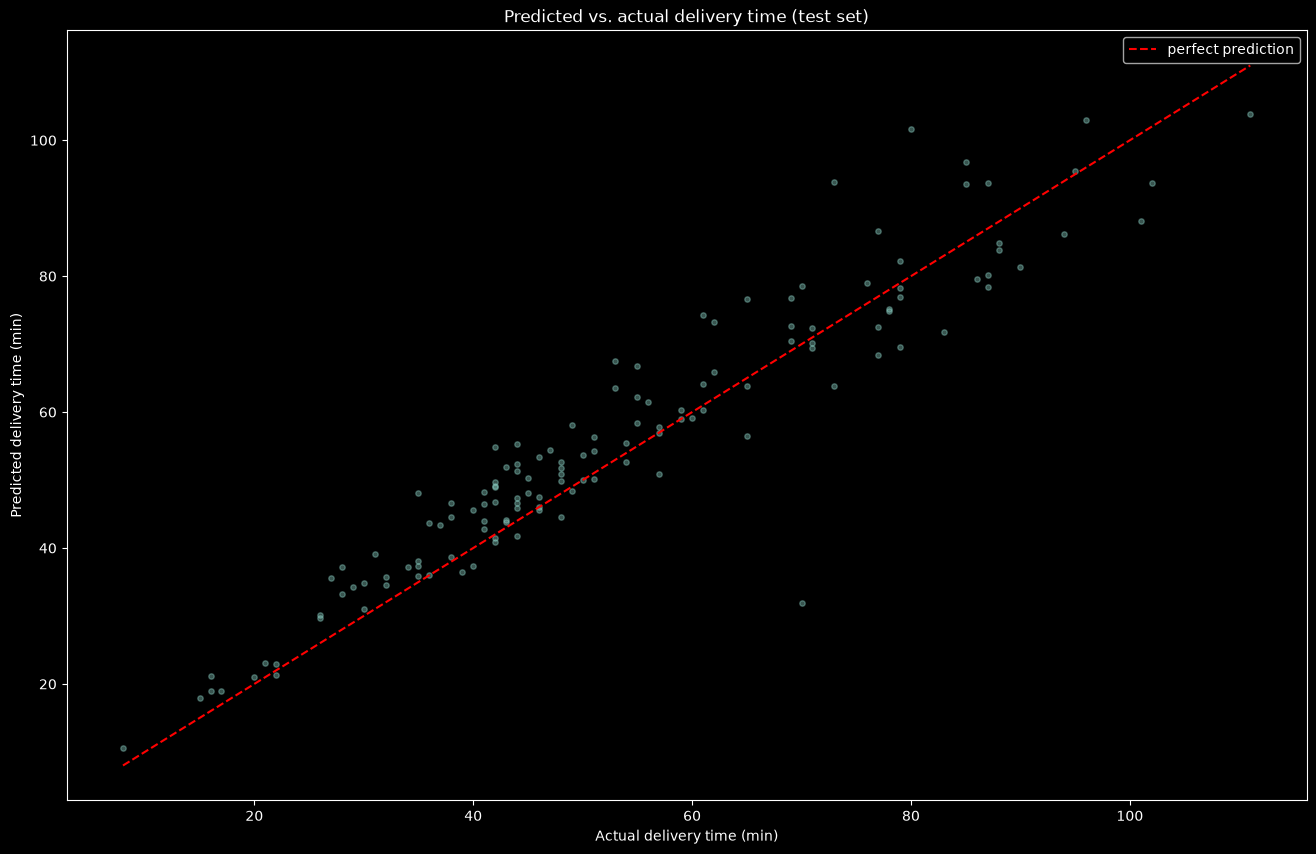

In [22]:
plt.figure(figsize=(16, 10))
plt.scatter(y_test, y_pred_test, alpha=0.4, s=15)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual delivery time (min)")
plt.ylabel("Predicted delivery time (min)")
plt.title("Predicted vs. actual delivery time (test set)")
plt.legend()
plt.show()


## 13. Summary

- We built **multiple linear regression** the concise PyTorch way: `nn.Linear` +
  `nn.MSELoss` + `torch.optim`, with data fed through `Dataset`/`DataLoader`.
- **Training error** (computed on data the model was fit to) is an optimistic estimate of
  performance; **generalization error**, approximated by held-out validation/test data, is
  what we actually care about.
- We use **three** splits: train (fit parameters), validation (tune hyperparameters and pick
  a model), test (one honest final number). Fitting preprocessing only on the training set
  avoids information leakage.


## Noted**

### 1.  Why `Traffic_Level` gets thermometer encoding and `Time_of_Day` stays one-hot

**`Traffic_Level` (Low < Medium < High): thermometer encoding.** Traffic congestion sits on
a single increasing scale — more congestion is unambiguously "more traffic" — and it's
reasonable to assume its effect on delivery time increases monotonically (High traffic is
never *faster* than Medium, which is never faster than Low). Thermometer encoding captures
that ordering while still letting each step (Low→Medium, Medium→High) have its own learned
size, which plain integer encoding (0, 1, 2) would not allow.

**`Time_of_Day` (Morning, Afternoon, Evening, Night): kept as one-hot.**

1. **It isn't really a scale, it's a cycle.** A day loops: Night is followed by Morning
   again, not by "more time." Any ordering we pick is a somewhat arbitrary slice of a
   circle, not a true 1-D ruler like traffic congestion.
2. **Thermometer encoding hard-codes monotonicity, and delivery time vs. time-of-day is
   probably** ***not*** **monotonic.** Real delivery times likely go up during morning
   rush, down mid-day, up again during evening rush, then down again at night — a
   non-monotonic, roughly two-peaked pattern. A monotonic encoding **cannot represent two
   separate peaks**; the model would be forced to average them into an incorrect, smoothed
   trend.
3. **One-hot doesn't have this problem.** It gives each period its own free weight with no
   ordering assumption at all, so it can represent "Morning and Evening are both slow,
   Afternoon and Night are both fast" just as easily as a monotonic pattern.

So the encoding used above is a deliberate mix: thermometer for the one feature where a
monotonic assumption is justified (`Traffic_Level`), one-hot for everything else, including
`Time_of_Day`.


### 2. This lab we focus on prepare data(checking/removing missing values,encoding), split dataset into three sets for train model, evaluate model during training, and test model after finishing training all of epoches. 

-> **In next session, we will move to learn generalization where anaysis on model training to understand what is overfitting training, underfitting training, fitting training, and technique of trainng model including early-stoping, and k-fold.**
